# Comparable Airbnb listings — similarity-based nearest neighbours

This notebook explores how to retrieve existing Airbnb listings comparable to a hypothetical listing. It mirrors the similarity definition used in the backend's SQLAlchemy query, but performs the calculations locally with **pandas and NumPy** so that each component can be inspected.

The approach uses **exact-match similarity** for categorical features, **IQR-scaled and clipped similarity** for numerical features, and **Jaccard similarity** for amenities. Every component is between **0 and 1**, where 1 is an exact match. The final score is the arithmetic mean of the components supplied by the hypothetical listing, and **larger scores indicate more similar listings**.

This is a *similarity-based nearest-neighbour ranking*, not a fitted `sklearn` KNN model.

In [1]:
from typing import Any
import pandas as pd
import numpy as np
from postgre_tools import Users, create_postgres_engine
import matplotlib.pyplot as plt


In [2]:
engine = create_postgres_engine(Users.AIRBNB.load_user())

# Set count to None if you want to fetch all rows
listings_row_count: int | None = None
amenities_row_count: int | None = None

if listings_row_count is not None and listings_row_count <= 0:
    raise ValueError("listings_row_count must be greater than 0")
if amenities_row_count is not None and amenities_row_count <= 0:
    raise ValueError("amenities_row_count must be greater than 0")

listings_query = "SELECT id, room_type, accommodates, bedrooms, beds, district FROM listings"
amenities_query = "SELECT * FROM listing_amenities"

if listings_row_count is not None:
    listings_query += f" LIMIT {listings_row_count}"

if amenities_row_count is not None:
    amenities_query += f" LIMIT {amenities_row_count}"

listings_df = pd.read_sql(listings_query, engine)
listing_amenities_df = pd.read_sql(amenities_query, engine)

engine.dispose()

In [3]:
print(f"Columns in listings_df: {listings_df.columns}")
print(f"\nData types in listings_df:\n{listings_df.dtypes}")
listings_df

Columns in listings_df: Index(['id', 'room_type', 'accommodates', 'bedrooms', 'beds', 'district'], dtype='str')

Data types in listings_df:
id                int64
room_type           str
accommodates      int64
bedrooms        float64
beds            float64
district            str
dtype: object


,id,room_type,accommodates,bedrooms,beds,district
0,145320,Private room,2,1.0,1.0,Södermalm
1,164448,Private room,2,NaN,2.0,Södermalm
2,220851,Private room,1,NaN,1.0,Kungsholmen
3,242188,Private room,1,NaN,1.0,Södermalm
4,273906,Entire home/apt,4,3.0,NaN,Södermalm
...,...,...,...,...,...,...
4801,1717861167246979973,Entire home/apt,2,1.0,1.0,Skarpnäck
4802,1718132464242032867,Private room,2,1.0,1.0,Järva
4803,1718263471917793029,Entire home/apt,2,1.0,1.0,Bromma
4804,1718288866708700915,Entire home/apt,2,1.0,1.0,Kungsholmen


## Features and distribution

The `id` column identifies a listing and is **not** used as a similarity feature. The categorical features are `room_type` and `district`; the numerical features are `accommodates`, `bedrooms`, and `beds`. Amenities are stored separately in `listing_amenities_df` and compared as **sets of distinct amenity names**.

We examine the numerical distributions before deciding how to scale their differences. The **interquartile range (IQR)** is Q3 − Q1; it measures the spread of the middle 50% of observations and is less sensitive to extreme observations than the standard deviation.

In [8]:
CATEGORICAL_COLUMNS = ["room_type", "district"]
NUMERICAL_COLUMNS = ["accommodates", "bedrooms", "beds"]
CLIPPING_THRESHOLD = 3.0

listings_df[NUMERICAL_COLUMNS].describe().T

,count,mean,std,min,25%,50%,75%,max
accommodates,4806.0,3.602788,2.089303,1.0,2.0,3.0,5.0,16.0
bedrooms,4109.0,1.920662,1.227736,0.0,1.0,1.0,3.0,12.0
beds,2882.0,2.364330,1.834288,1.0,1.0,2.0,3.0,22.0


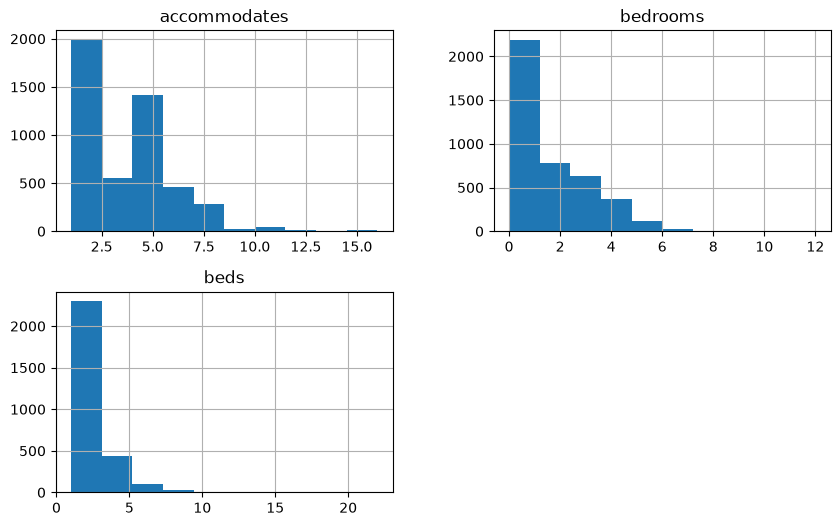

In [9]:
# Create a histogram of the numerical columns
listings_df[NUMERICAL_COLUMNS].hist(figsize=(10, 6))
plt.show()

## Defining a normalized similarity score

For a hypothetical listing $h$ and an existing listing $x$, calculate the similarity for each **specified** feature and average the active components:

$$
S(h,x) = \frac{\sum_{k=1}^{n}\delta_k s_k(h,x)}{\sum_{k=1}^{n}\delta_k},
\qquad
\delta_k = \begin{cases}1 & \text{if feature }k\text{ is specified}\\0 & \text{otherwise.}\end{cases}
$$

All $s_k(h,x)$ lie in $[0,1]$. A hypothetical feature set to `None` is omitted entirely (it contributes neither to the numerator nor to the denominator). Every specified feature contributes **equally**; the whole amenities set counts as **one** component. At least one feature must be specified.

### Categorical features

$$s_k(h,x) = \begin{cases}1 & h_k=x_k\\0 & h_k\neq x_k.\end{cases}$$

A missing value in an existing listing is a non-match (similarity 0) for a specified categorical field.

### Numerical features

For each numerical feature, compute $IQR_k=Q_{0.75,k}-Q_{0.25,k}$ across existing listings, then use:

$$s_k(h,x) = 1-\frac{\min\left(\frac{|h_k-x_k|}{a_k},\,c\right)}{c},\qquad c=3,$$

where $a_k=IQR_k$ unless the IQR is zero or missing, in which case $a_k=1$. Missing numerical values in existing listings receive similarity **0**. Thus equal values score 1, a difference of one IQR scores $1-1/3\approx0.667$, and differences of three IQRs or more score 0.

IQR division makes differences across numerical columns more comparable. The clipping threshold is a **heuristic**, not a fitted parameter. Unlike the notebook's earlier approach, **each numerical feature contributes its own similarity**; we do not calculate a combined Euclidean distance. Subtracting the median is unnecessary for pairwise differences because the medians would cancel.

### Amenities (Jaccard similarity)

For the hypothetical amenity set $A$ and an existing listing's amenity set $B$:

$$s_J(A,B) = \frac{|A\cap B|}{|A\cup B|}.$$

If both sets are empty, define similarity as **1**. Repeated amenity rows do not affect the result because amenities are treated as sets. An empty hypothetical list `[]` is *specified* (it is compared), while `None` means *exclude amenities* from the score.

These choices match the backend's SQL expression, including zero-IQR fallback, missing-value penalties, and sorting by descending similarity.

## Hypothetical listing

Change the values below to experiment with the ranking. Set any individual feature to `None` to leave it out of the similarity calculation; set `amenities` to `None` to omit the Jaccard component.

In [10]:

HYPOTHETICAL_LISTING = {
    "room_type": "Private room",
    "accommodates": 2,
    "bedrooms": 1,
    "beds": 1,
    "district": "Södermalm",
    "amenities": [
        "Bathtub",
        "Blender",
        "Body soap",
        "Cleaning products",
        "Coffee",
        "Coffee maker",
        "Cooking basics",
        "Dining table",
        "Dishes and silverware",
        "Dishwasher",
        "Elevator",
        "Essentials",
        "Extra pillows and blankets",
        "Freezer",
        "Hair dryer",
        "Hangers",
        "Host greets you",
        "Hot water",
        "Hot water kettle",
        "Iron",
        "Kitchen",
        "Microwave",
        "Outdoor dining area",
        "Outdoor furniture",
        "Oven",
        "Refrigerator",
        "Shampoo",
        "Stove",
        "Toaster",
        "Wifi",
        "Wine glasses",
    ]
}

## Pandas/NumPy implementation

The function below returns one similarity per listing. Optionally, `return_components=True` returns the individual feature contributions alongside the overall score, making it easier to explain and debug results. IQRs are estimated from the supplied `listings` DataFrame, so a sampled dataset can yield different scales from the full PostgreSQL table.

In [11]:
def similarity(
    hypo_listing: dict,
    listings: pd.DataFrame,
    amenities: pd.DataFrame,
    *,
    return_components: bool = False,
) -> pd.Series | pd.DataFrame:
    """Calculate similarities to a hypothetical listing using pandas/NumPy.

    Every specified categorical/numerical feature contributes one score in
    [0, 1]; amenities contribute one Jaccard score when specified.
    The final score is their unweighted mean (higher means more similar).
    """
    components: dict[str, pd.Series] = {}

    # 1. Categorical similarities (exact matches).
    for column_name in CATEGORICAL_COLUMNS:
        value = hypo_listing.get(column_name)
        if value is None:
            continue
        components[column_name] = (
            listings[column_name].eq(value).fillna(False).astype(float)
        )

    # 2. Numerical similarities, with scales estimated from all listings.
    numerical_fields = [
        name for name in NUMERICAL_COLUMNS
        if hypo_listing.get(name) is not None
    ]
    if numerical_fields:
        values = listings[numerical_fields].astype(float)
        scales = values.quantile(0.75) - values.quantile(0.25)
        scales = scales.replace(0, np.nan).fillna(1.0)

        for column_name in numerical_fields:
            difference = (
                (values[column_name] - float(hypo_listing[column_name]))
                .abs() / scales[column_name]
            )
            clipped = difference.clip(upper=CLIPPING_THRESHOLD).fillna(
                CLIPPING_THRESHOLD
            )
            components[column_name] = 1.0 - clipped / CLIPPING_THRESHOLD

    # 3. Jaccard similarity for the complete amenity set (one component).
    if hypo_listing.get("amenities") is not None:
        query_amenities = set(hypo_listing["amenities"])
        amenities_by_listing = (
            amenities.groupby("listing_id")["amenity"].agg(set).to_dict()
        )

        def jaccard(listing_id: Any) -> float:
            existing = amenities_by_listing.get(listing_id, set())
            intersection = len(query_amenities & existing)
            union = len(query_amenities | existing)
            return intersection / union if union else 1.0

        components["amenities"] = listings["id"].map(jaccard).astype(float)

    if not components:
        raise ValueError("At least one similarity feature must be specified.")

    component_scores = pd.DataFrame(components, index=listings.index)
    overall = component_scores.sum(axis=1) / len(components)
    overall.name = "similarity"

    # Descending similarity; ID is the deterministic tie-breaker (as in SQL).
    result = component_scores.assign(similarity=overall, id=listings["id"])
    result = result.sort_values(["similarity", "id"], ascending=[False, True])

    if return_components:
        return result
    return result["similarity"]


In [12]:
# Comparable listings ranked from most similar to least similar.
component_results = similarity(
    HYPOTHETICAL_LISTING,
    listings_df,
    listing_amenities_df,
    return_components=True,
)
component_results.head(10)

,room_type,district,accommodates,bedrooms,beds,amenities,similarity,id
0,1.0,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,145320
4616,1.0,1.0,1.000000,1.000000,1.000000,0.700000,0.950000,1690596437170593286
2351,1.0,1.0,1.000000,1.000000,1.000000,0.500000,0.916667,922961807547796328
4109,1.0,1.0,0.888889,1.000000,1.000000,0.560976,0.908311,1530593304240462848
2352,1.0,1.0,1.000000,1.000000,1.000000,0.439024,0.906504,922979571285623648
2472,1.0,1.0,1.000000,1.000000,1.000000,0.375000,0.895833,965057532185049630
2179,1.0,1.0,1.000000,0.833333,0.833333,0.648649,0.885886,883362046967063483
524,1.0,1.0,0.888889,0.833333,1.000000,0.540541,0.877127,18559674
1144,1.0,1.0,1.000000,1.000000,1.000000,0.257143,0.876190,40459643
4359,1.0,1.0,1.000000,1.000000,1.000000,0.236842,0.872807,1639861971713619715


## Inspect the highest-ranked listings

Join the scores with the original listing characteristics so that we can interpret the retrieved neighbours. The `similarity` column ranges from 0 to 1, **not a distance**. A higher score indicates a closer match under the defined feature comparisons.

In [13]:
top_n = 10
ranked_listings = (
    component_results.head(top_n)
    .join(listings_df.drop(columns="id"), rsuffix="_listing")
)
ranked_listings

,room_type,district,accommodates,bedrooms,beds,amenities,similarity,id,room_type_listing,accommodates_listing,bedrooms_listing,beds_listing,district_listing
0,1.0,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,145320,Private room,2,1.0,1.0,Södermalm
4616,1.0,1.0,1.000000,1.000000,1.000000,0.700000,0.950000,1690596437170593286,Private room,2,1.0,1.0,Södermalm
2351,1.0,1.0,1.000000,1.000000,1.000000,0.500000,0.916667,922961807547796328,Private room,2,1.0,1.0,Södermalm
4109,1.0,1.0,0.888889,1.000000,1.000000,0.560976,0.908311,1530593304240462848,Private room,1,1.0,1.0,Södermalm
2352,1.0,1.0,1.000000,1.000000,1.000000,0.439024,0.906504,922979571285623648,Private room,2,1.0,1.0,Södermalm
2472,1.0,1.0,1.000000,1.000000,1.000000,0.375000,0.895833,965057532185049630,Private room,2,1.0,1.0,Södermalm
2179,1.0,1.0,1.000000,0.833333,0.833333,0.648649,0.885886,883362046967063483,Private room,2,2.0,2.0,Södermalm
524,1.0,1.0,0.888889,0.833333,1.000000,0.540541,0.877127,18559674,Private room,1,2.0,1.0,Södermalm
1144,1.0,1.0,1.000000,1.000000,1.000000,0.257143,0.876190,40459643,Private room,2,1.0,1.0,Södermalm
4359,1.0,1.0,1.000000,1.000000,1.000000,0.236842,0.872807,1639861971713619715,Private room,2,1.0,1.0,Södermalm


## Sanity checks without PostgreSQL

These small synthetic cases test perfect equality, mismatched categories, missing numerical values, Jaccard intersections, both-empty amenity sets, and the distinction between `None` (ignored) and `[]` (explicitly empty). The tests do not depend on the database connection.

In [14]:
test_listings = pd.DataFrame({
    "id": [1, 2, 3],
    "room_type": ["Private room", "Entire home", "Private room"],
    "district": ["A", "B", "A"],
    "accommodates": [2.0, 4.0, np.nan],
    "bedrooms": [1, 2, 3],
    "beds": [1, 2, 3],
})
test_amenities = pd.DataFrame({
    "listing_id": [1, 1, 2],
    "amenity": ["Wifi", "Kitchen", "Wifi"],
})

# With just room_type and amenities, listing 1 is an exact match.
query = {"room_type": "Private room", "amenities": ["Wifi", "Kitchen"]}
scores = similarity(query, test_listings, test_amenities, return_components=True)
assert np.isclose(scores.set_index("id").loc[1, "similarity"], 1.0)
assert np.isclose(scores.set_index("id").loc[2, "similarity"], 0.25)

# A missing existing value scores 0 for a specified numerical feature.
num_scores = similarity({"accommodates": 2}, test_listings, test_amenities)
assert np.isclose(num_scores.loc[2], 0.0)

# Both amenity sets empty: listing 3 has no amenities, so scores 1.
empty_scores = similarity({"amenities": []}, test_listings, test_amenities)
assert np.isclose(empty_scores.loc[2], 1.0)

# None excludes amenities altogether.
ignored = similarity({"room_type": "Private room", "amenities": None}, test_listings, test_amenities)
assert np.isclose(ignored.loc[0], 1.0)

assert scores["similarity"].between(0, 1).all()
print("All similarity sanity checks passed.")
scores

All similarity sanity checks passed.


,room_type,amenities,similarity,id
0,1.0,1.0,1.00,1
2,1.0,0.0,0.50,3
1,0.0,0.5,0.25,2


## Interpretation and limitations

The score is an **interpretable heuristic ranking**, not a probability that listings are equivalent and not a prediction of nightly price. All active components receive equal weight, including amenities as a single feature. Exact-match district comparisons do not account for geographically neighbouring areas, and Jaccard similarity treats all amenities as equally important.

The IQR fallback of 1 for zero-IQR columns and the clipping threshold of 3 are deliberate implementation choices. Inspect their effect on the top neighbours and consider sensitivity analysis before using the ranking in the application. For strict comparison with the SQL backend, use the same full listing population for IQR estimation, the same data-cleaning assumptions, and the same hypothetical input.

The notebook's percentile calculation (`pandas.quantile`) and PostgreSQL's `percentile_cont` both use continuous interpolation by default, so they should agree on the same non-null numeric inputs apart from floating-point differences.